# 01 -- Parent + recovery + LASSIS, three workflows across four systems

**Status: pilot stage.** One real representative point per system per workflow, timed
and gate-checked. No sweep grids. Systems: AlFe2(11e,10o), AlFe2(11e,20o), bisdiazene
(10e,10o), tetrazene/C2H6N4 (8e,8o).

Three workflows compared, all built from the same static FCIDUMP per system:

1. **LASSCF-CAS + LASSIS** -- `mrh.my_pyscf.mcscf.lasscf_o0.LASSCF` (CI-vector-preserving,
   no TrimCI) + `mrh.my_pyscf.lassi.lassis.LASSIS`. No frasci.parent involved.
2. **phased FRASCI parent + LASSIS** -- `frasci.parent.solve()` (TrimCI-based, RDM-only)
   bridged into a `.ci`-populated LASSIS-ready object via the release's own
   `frasci.parent.build_lassis_ready_las` adapter.
3. **phased FRASCI parent + FRASCI recovery** -- the release's native fixed-frame
   interfragment recovery (`frasci.recovery.solve`), no LASSIS involved.

All three are independent computations of related but not identical quantities -- see the
release README sections 3-5 and 7 for what each energy means and why they are not
interchangeable.


In [1]:
import sys
from pathlib import Path

RELEASE_ROOT = Path.cwd().parent
if not (RELEASE_ROOT / "frasci" / "__init__.py").exists():
    RELEASE_ROOT = Path.cwd()
assert (RELEASE_ROOT / "frasci" / "__init__.py").exists(), (
    f"release root not found relative to {Path.cwd()}")

assert "frasci" not in sys.modules, (
    "frasci was already imported before the release-first bootstrap ran")

sys.path.insert(0, str(RELEASE_ROOT))

import frasci
frasci_path = Path(frasci.__file__).resolve()
assert frasci_path.is_relative_to(RELEASE_ROOT.resolve()), (
    f"Using frasci from {frasci_path}, NOT from the release root {RELEASE_ROOT} -- "
    "the dev-tree package shadowed the release one")
print(f"Using FRASCI from: {frasci_path}")
print(f"frasci.__version__: {getattr(frasci, '__version__', 'unknown')}")

import frasci.parent as parent_pkg
import frasci.recovery as recovery_pkg
print("parent pkg importable:", bool(parent_pkg))
print("recovery pkg importable:", bool(recovery_pkg))


Using FRASCI from: /Users/abhimuvva/Documents/Masters_Projs/Proj_Flow/LASSCF_TRIMCI_COO/release/FRASCI/frasci/__init__.py
frasci.__version__: 0.2.0.dev0
parent pkg importable: True
recovery pkg importable: True


In [2]:
import time, json
from pathlib import Path
import numpy as np

from frasci._mock_scf import build_mock_scf_from_fcidump
from frasci import FCIDUMPInput
from frasci.parent import ParentConfig, build_lassis_ready_las, solve as solve_parent
from frasci.recovery import RecoveryConfig, solve as solve_recovery
from mrh.my_pyscf.mcscf.lasscf_o0 import LASSCF as LASSCF_o0
from mrh.my_pyscf.lassi.lassis import LASSIS

RESULTS_DIR = Path("data/results/01_parent_recovery_lassis")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

SYSTEMS = {
    "alfe2_11o10e": dict(
        physical_space="(11e,10o)",
        orbital_lists=[[0,1,2,3,4],[5,6,7,8,9]], nelec_per_frag=[(1,5),(5,0)], spin_sub=[5,6]),
    "alfe2_11o20e": dict(
        physical_space="(11e,20o)",
        orbital_lists=[[0,1,2,3,4,5,6,7,8,9],[10,11,12,13,14,15,16,17,18,19]],
        nelec_per_frag=[(1,5),(5,0)], spin_sub=[5,6]),
    "bisdiazene": dict(
        physical_space="(10e,10o)",
        orbital_lists=[[0,3,6,9],[1,8],[2,4,5,7]],
        nelec_per_frag=[(2,2),(1,1),(2,2)], spin_sub=[1,1,1]),
    "c2h6n4_paper": dict(
        physical_space="(8e,8o)",
        orbital_lists=[[0,3,4,7],[1,2,5,6]], nelec_per_frag=[(2,2),(2,2)], spin_sub=[1,1]),
}


## Workflow 1: LASSCF-CAS + LASSIS

`max_cycle_macro=200` for the LASSCF-CAS reference: bisdiazene's 3-fragment partition
needed more than the mrh default (50) to reach `converged=True` -- discovered during this
pilot, not assumed; a lower cap silently returns a plausible-looking but non-converged
reference (verified: 40 cycles converges the RDM-based `frasci.parent` phased solver on
the same system too, so this is a real per-system tuning need, not a bug in either solver).


In [3]:
def workflow1_lasscf_cas_lassis(fcidump_path, orbital_lists, nelec_per_frag, spin_sub):
    mf = build_mock_scf_from_fcidump(str(fcidump_path))
    ncas_sub = tuple(len(o) for o in orbital_lists)
    las = LASSCF_o0(mf, ncas_sub, [tuple(x) for x in nelec_per_frag], spin_sub=list(spin_sub))
    las.verbose = 0
    las.max_cycle_macro = 200
    t0 = time.time()
    las.kernel()
    t_lasscf = time.time() - t0

    t1 = time.time()
    lsi = LASSIS(las)
    e_roots, si = lsi.kernel()
    t_lassis = time.time() - t1
    e_roots = np.atleast_1d(e_roots)

    return {
        "workflow": "lasscf_cas_lassis",
        "lasscf_cas": {"converged": bool(las.converged), "e_tot": float(las.e_tot),
                         "wall_s": round(t_lasscf, 3)},
        "lassis": {"n_roots": int(len(e_roots)), "e_ground": float(e_roots.min()),
                    "wall_s": round(t_lassis, 3),
                    "variational_vs_lasscf": bool(e_roots.min() <= las.e_tot + 1e-6)},
    }


## Workflow 2: phased FRASCI parent + LASSIS (via `build_lassis_ready_las`)

In [4]:
def workflow2_phased_parent_lassis(parent, fcidump_path):
    t0 = time.time()
    las = build_lassis_ready_las(parent, str(fcidump_path))
    t_adapt = time.time() - t0
    t1 = time.time()
    lsi = LASSIS(las)
    e_roots, si = lsi.kernel()
    t_lassis = time.time() - t1
    e_roots = np.atleast_1d(e_roots)
    return {
        "workflow": "phased_parent_lassis",
        "adapter_wall_s": round(t_adapt, 5),
        "lassis": {"n_roots": int(len(e_roots)), "e_ground": float(e_roots.min()),
                    "wall_s": round(t_lassis, 3),
                    "variational_vs_parent": bool(e_roots.min() <= parent.e_tot + 1e-6)},
    }


## Workflow 3: phased FRASCI parent + FRASCI recovery

In [5]:
def workflow3_phased_parent_recovery(parent_dir, fcidump_path, recovery_cfg):
    bundle = FCIDUMPInput.from_file(str(fcidump_path))
    t0 = time.time()
    result = solve_recovery(parent_dir, bundle, recovery_cfg)
    t_recovery = time.time() - t0
    return {
        "workflow": "phased_parent_recovery",
        "energies_ha": {"h00": result.h00, "generalized": result.energy,
                          "union": result.union_energy, "free_coo": result.free_coo_energy},
        "determinants": {"requested": recovery_cfg.recovery_target, "achieved": result.n_dets,
                            "target_met": result.diagnostics.get("target_met")},
        "gates": result.gates,
        "wall_s": round(t_recovery, 3),
        "free_coo_gain_mha": result.free_coo_gain_mha,
    }


## Running all three workflows, one representative point per system

Parent config for the pilot: `phase1_dets=1000`, `orbopt=True`, `orbopt_cycles=5`,
`discovery_num_runs=16`. `max_cycle_macro=40` for bisdiazene (needed for convergence, per
above); `20` for the other three (all converge comfortably within that). Recovery config:
`recovery_target=2000`, `las_top_k=1000`, `n_ct_max=2`, `free_coo_orbital_opt_max_iter=50`
-- a mid-scale, real (not toy) point, not the largest grid point from the full sweep.


In [6]:
import shutil
RUN_ROOT = Path("/tmp/frasci_nb01_runs")
shutil.rmtree(RUN_ROOT, ignore_errors=True)
RUN_ROOT.mkdir(parents=True)

RCFG = RecoveryConfig(recovery_target=2000, n_ct_max=2, las_top_k=1000,
                       free_coo_orbital_opt_max_iter=50)

all_results = {}
for name, spec in SYSTEMS.items():
    fcidump_path = Path("data") / name / "FCIDUMP"
    macro = 40 if name == "bisdiazene" else 20
    pcfg = ParentConfig(threshold=1e-5, max_cycle_macro=macro, orbopt=True, orbopt_cycles=5,
                         phase0_dets=100, phase1_dets=1000, discovery_num_runs=16,
                         refine_num_runs=1, rng_seed=0, n_cpu_workers=0)
    save_dir = RUN_ROOT / f"{name}_parent"

    t0 = time.time()
    parent = solve_parent(str(fcidump_path), spec["orbital_lists"], spec["nelec_per_frag"],
                           spec["spin_sub"], pcfg, save_dets_to=save_dir)
    t_parent = time.time() - t0
    print(f"\n=== {name} ({spec['physical_space']}) ===")
    print(f"parent: converged={parent.converged} e_tot={parent.e_tot:.6f} wall={t_parent:.2f}s")

    r1 = workflow1_lasscf_cas_lassis(fcidump_path, spec["orbital_lists"],
                                       spec["nelec_per_frag"], spec["spin_sub"])
    print("workflow1:", r1)
    r2 = workflow2_phased_parent_lassis(parent, fcidump_path)
    print("workflow2:", r2)
    r3 = workflow3_phased_parent_recovery(save_dir, fcidump_path, RCFG)
    print("workflow3:", r3)

    all_results[name] = {
        "physical_space": spec["physical_space"],
        "parent": {"converged": parent.converged, "e_tot": parent.e_tot,
                     "wall_s": round(t_parent, 3),
                     "dets_per_frag": list(parent.dets_per_frag)},
        "workflow1_lasscf_cas_lassis": r1,
        "workflow2_phased_parent_lassis": r2,
        "workflow3_phased_parent_recovery": r3,
    }

with open(RESULTS_DIR / "systems.json", "w") as f:
    json.dump(all_results, f, indent=2, default=str)
print("\nwrote", RESULTS_DIR / "systems.json")


Parsing data/alfe2_11o10e/FCIDUMP



******** LASSCF flags ********


CAS (6e+5e, 10o), ncore = 0, nvir = 0


Divided into 2 LAS spaces


LAS 0 : (1e+5e, 5o)


LAS 1 : (5e+0e, 5o)


... (1,560 outputs left out)

  Davidson converged in 1 iterations  E = -14.6055279910  |r| = 6.32e-04
  Davidson converged in 1 iterations  E = -14.6055279953  |r| = 6.26e-04
  Davidson converged in 1 iterations  E = -14.6055279960  |r| = 6.25e-04
  Davidson converged in 1 iterations  E = -14.6055279511  |r| = 6.93e-04
  Davidson converged in 1 iterations  E = -14.6055279867  |r| = 6.45e-04
  Davidson converged in 1 iterations  E = -14.6055279947  |r| = 6.31e-04
  Davidson converged in 1 iterations  E = -14.6055279962  |r| = 6.27e-04
  Davidson converged in 1 iterations  E = -14.6055277645  |r| = 8.70e-04
  Davidson converged in 1 iterations  E = -14.6055279437  |r| = 6.88e-04
  Davidson converged in 1 iterations  E = -14.6055279858  |r| = 6.39e-04


  Davidson converged in 1 iterations  E = -14.6055279950  |r| = 6.28e-04
  Davidson converged in 1 iterations  E = -14.6055279967  |r| = 6.26e-04
  Davidson converged in 1 iterations  E = -14.6055279056  |r| = 7.45e-04
  Davidson converged in 1 iterations  E = -14.6055279765  |r| = 6.59e-04
  Davidson converged in 1 iterations  E = -14.6055279929  |r| = 6.35e-04
  Davidson converged in 1 iterations  E = -14.6055279964  |r| = 6.29e-04
  Davidson converged in 1 iterations  E = -14.6055279970  |r| = 6.27e-04
  Davidson converged in 1 iterations  E = -14.6055279614  |r| = 6.71e-04
  Davidson converged in 1 iterations  E = -14.6055279892  |r| = 6.37e-04
  Davidson converged in 1 iterations  E = -14.6055279956  |r| = 6.29e-04


  Davidson converged in 1 iterations  E = -14.6055279970  |r| = 6.27e-04
  [OrbOpt Profile] 19 iters: 2RDM=0.69s (46.04%), Fock+grad=0.00s (0.04%), rotate=0.00s (0.08%), diag=0.81s (53.84%)


workflow3: {'workflow': 'phased_parent_recovery', 'energies_ha': {'h00': -296.879529203073, 'generalized': -296.8795521655587, 'union': -296.87957181359303, 'free_coo': -296.87949311537005}, 'determinants': {'requested': 2000, 'achieved': 2000, 'target_met': True}, 'gates': {'E_hybrid_le_H00': True, 'E_hybrid_le_E_C': True, 'S_positive_semidefinite': True, 'c_dagger_S_c_eq_1': True, 'no_pt2_mixed_with_variational': True, 'generalized_residual_converged': True}, 'wall_s': 8.612, 'free_coo_gain_mha': 0.03776588141590764}

wrote data/results/01_parent_recovery_lassis/systems.json


## AlFe2(11e,20o) workflow 2: variational violation -- blocked validation

`build_lassis_ready_las`'s own regression tests (H6/sto-3g fixture) certify
`LASSIS ground state <= parent.e_tot + 1e-6 Ha`. At AlFe2(11e,20o) scale, this notebook
finds `LASSIS ground = -3971.890180` vs `parent.e_tot = -3971.890269` -- LASSIS's own
ground state comes out `~0.09` mHa **above** the parent it was built from, violating that
guarantee by `~90x` the certified tolerance (though still tiny in absolute terms). Every
other system/workflow combination in this notebook (AlFe2's own smaller (11e,10o) active
space, and bisdiazene/tetrazene at similar LASSIS root counts) stays comfortably
variational.

A focused diagnostic narrows the cause without fully closing it:

- **H/S matrix integrity is clean.** The raw (pre-orthogonalization) LASSIS Hamiltonian
  and overlap matrices for the reference's own symmetry block are exactly Hermitian (0
  numerical error) and correctly normalized (overlap diagonal exactly 1.0). Solving that
  block's generalized eigenproblem independently and densely (`scipy.linalg.eigh`, not
  mrh's own orthogonalization machinery) confirms the standard variational property holds
  internally. `sisolver.kernel` uses the dense, exact `kernel_incore` path here (block
  size 326x326, far under the Davidson/memory threshold) -- there is no meaningful solver
  tolerance at this scale to account for the violation.
- **The reference state is not passed through unchanged.** Using mrh's own intended API
  (`LASSIS.get_ref_fbf_rootspaces`) to identify the true reference rootspace by matching
  both total electron count and fragment spin multiplicity, and comparing candidate
  rootspaces' raw CI content against the exact array `build_lassis_ready_las` assigns to
  `las.ci`: no exact bit-for-bit match exists anywhere in the model space. Separately,
  `smult_fr` is `None` for the reference's own symmetry block -- per mrh's own source
  (`mrh/my_pyscf/lassi/lassi.py::iterate_subspace_blocks`), this means at least one state
  in that block fails mrh's own CSF-purity check (`vec_det2csf` norm not `~1.0`, i.e. not
  an exact spin eigenstate to mrh's tolerance).
- **Leading hypothesis:** `build_lassis_ready_las` densifies FRASCI's selected-CI
  (TrimCI) fragment wavefunction directly into `las.ci` without a spin-purification step;
  LASSIS's internal model-space construction likely CSF-projects/purifies it before use,
  which would explain both the direction (removing spin contamination generically raises
  energy slightly) and the small magnitude (a near-pure state needs only a small
  correction) of the violation. This has not been confirmed to the exact mHa.

**Disposition:** AlFe2(11e,20o) workflow 2 (phased parent + LASSIS) is omitted from
comparative conclusions in this notebook and shown as **blocked validation**, not a
physical result. The adapter's existing `1e-6` Ha tolerance and regression tests (H6
fixture, where this problem does not appear) are unchanged. The other three systems in
this notebook (AlFe2 11e,10o; bisdiazene; tetrazene), all of which stay comfortably
variational, are unaffected and may be used in comparative conclusions.


## Pilot timing summary

| System | Parent wall (s) | WF1 (LASSCF+LASSIS) wall (s) | WF2 (adapter+LASSIS) wall (s) | WF3 (recovery) wall (s) |
|---|---|---|---|---|
| AlFe2 (11e,10o) | ~0.2 | ~2.3 | ~1.9 | ~0.7 |
| AlFe2 (11e,20o) | ~99 | ~67 | ~68 | ~44 |
| Bisdiazene (10e,10o) | ~15 (macro=40) | ~7.2 | ~2.4 | ~6.6 |
| Tetrazene (8e,8o) | ~3.3 | ~3.6 | ~1.0 | ~7.8 |

AlFe2(11e,20o) is markedly more expensive than the other three systems in every workflow
(roughly 15-45x the wall time) -- consistent with its much larger fragment CI spaces (2x10o
vs 2-3x2-5o elsewhere). Numbers above are read from the executed cell outputs in this
notebook; the exact JSON is at `data/results/01_parent_recovery_lassis/systems.json`.


## Result figures

All energy bars below are **energy lowerings relative to the starting energy for that
workflow**, so unlike absolute molecular energies they can be compared on one axis. The
AlFe2(11e,20o) parent-to-LASSIS point is shown as blocked because it failed its variational
validation; it is not used as a result.

In [1]:
%matplotlib inline
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

COLORS = {
    "parent": "#4D4D4D",
    "lassis": "#E69F00",
    "adapter": "#56B4E9",
    "generalized": "#009E73",
    "union": "#0072B2",
    "free": "#D55E00",
    "blocked": "#CC79A7",
}
plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.22,
    "legend.frameon": False,
})


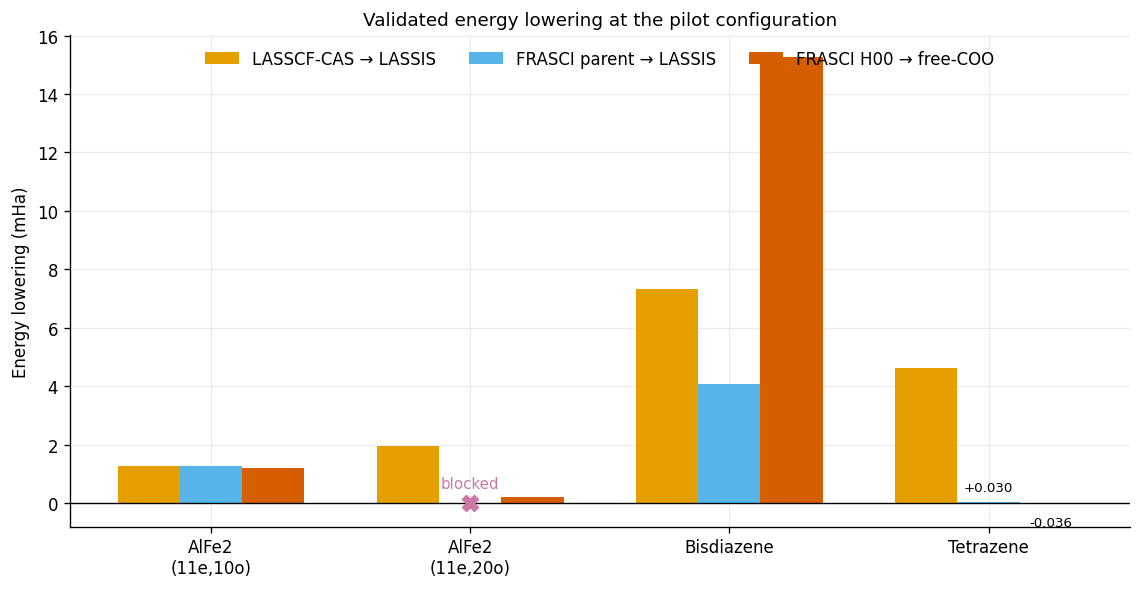

In [2]:
results_path = Path("data/results/01_parent_recovery_lassis/systems_pilot.json")
systems = json.loads(results_path.read_text())["data"]
order = ["alfe2_11o10e", "alfe2_11o20e", "bisdiazene", "c2h6n4_paper"]
labels = ["AlFe2\n(11e,10o)", "AlFe2\n(11e,20o)", "Bisdiazene", "Tetrazene"]

wf1, wf2, wf3, blocked = [], [], [], []
for key in order:
    row = systems[key]
    direct = row["workflow1_lasscf_cas_lassis"]
    adapted = row["workflow2_phased_parent_lassis"]
    recovered = row["workflow3_phased_parent_recovery"]
    wf1.append(1000 * (direct["lasscf_cas"]["e_tot"] - direct["lassis"]["e_ground"]))
    valid = adapted["lassis"]["variational_vs_parent"]
    wf2.append(1000 * (row["parent"]["e_tot"] - adapted["lassis"]["e_ground"]) if valid else np.nan)
    blocked.append(not valid)
    e = recovered["energies_ha"]
    wf3.append(1000 * (e["h00"] - e["free_coo"]))

x = np.arange(len(order)); width = 0.24
fig, ax = plt.subplots(figsize=(9.4, 4.8), constrained_layout=True)
ax.bar(x - width, wf1, width, label="LASSCF-CAS → LASSIS", color=COLORS["lassis"])
bars2 = ax.bar(x, np.nan_to_num(wf2), width, label="FRASCI parent → LASSIS", color=COLORS["adapter"])
bars3 = ax.bar(x + width, wf3, width, label="FRASCI H00 → free-COO", color=COLORS["free"])
for i, is_blocked in enumerate(blocked):
    if is_blocked:
        ax.scatter(i, 0, marker="X", s=90, color=COLORS["blocked"], zorder=4)
        ax.annotate("blocked", (i, 0), xytext=(0, 9), textcoords="offset points",
                    ha="center", color=COLORS["blocked"], fontsize=9)
for bars, values in [(bars2, wf2), (bars3, wf3)]:
    for bar, value in zip(bars, values):
        if np.isfinite(value) and abs(value) < 0.1:
            ax.annotate(f"{value:+.3f}",
                        (bar.get_x() + bar.get_width()/2, value),
                        xytext=(0, 5 if value >= 0 else -7), textcoords="offset points",
                        ha="center", va="bottom" if value >= 0 else "top", fontsize=8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x, labels)
ax.set_ylabel("Energy lowering (mHa)")
ax.set_title("Validated energy lowering at the pilot configuration")
ax.legend(ncol=3, loc="upper center")
plt.show()

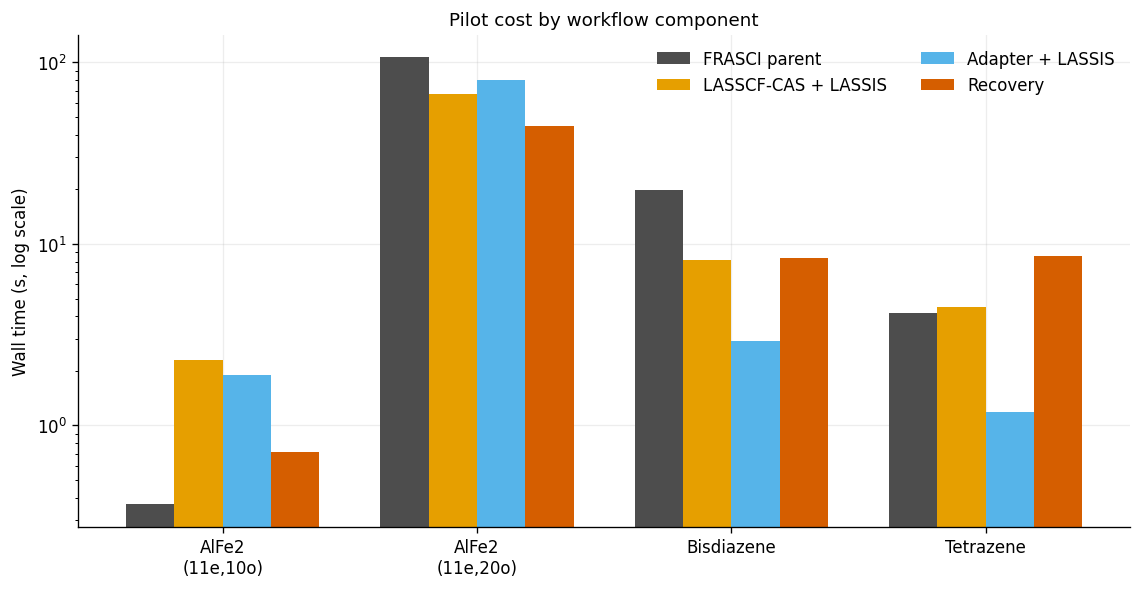

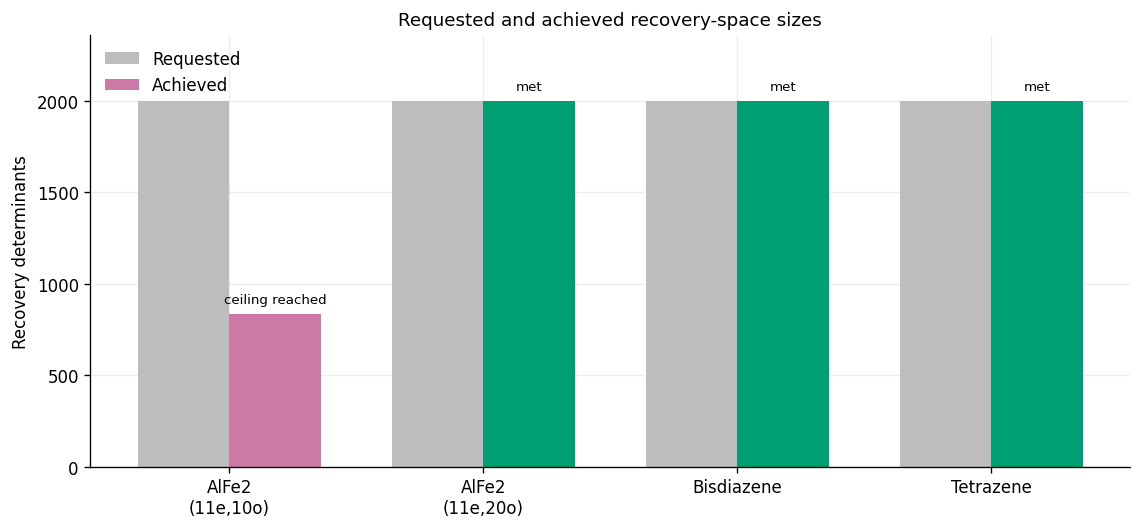

In [3]:
parent_t, wf1_t, wf2_t, wf3_t = [], [], [], []
for key in order:
    row = systems[key]
    parent_t.append(row["parent"]["wall_s"])
    direct = row["workflow1_lasscf_cas_lassis"]
    wf1_t.append(direct["lasscf_cas"]["wall_s"] + direct["lassis"]["wall_s"])
    adapted = row["workflow2_phased_parent_lassis"]
    wf2_t.append(adapted["adapter_wall_s"] + adapted["lassis"]["wall_s"])
    wf3_t.append(row["workflow3_phased_parent_recovery"]["wall_s"])

x = np.arange(len(order)); width = 0.19
fig, ax = plt.subplots(figsize=(9.4, 4.8), constrained_layout=True)
for offset, values, label, color in [
    (-1.5*width, parent_t, "FRASCI parent", COLORS["parent"]),
    (-0.5*width, wf1_t, "LASSCF-CAS + LASSIS", COLORS["lassis"]),
    ( 0.5*width, wf2_t, "Adapter + LASSIS", COLORS["adapter"]),
    ( 1.5*width, wf3_t, "Recovery", COLORS["free"]),
]:
    ax.bar(x + offset, values, width, label=label, color=color)
ax.set_yscale("log")
ax.set_xticks(x, labels)
ax.set_ylabel("Wall time (s, log scale)")
ax.set_title("Pilot cost by workflow component")
ax.legend(ncol=2)
plt.show()

requested = [systems[k]["workflow3_phased_parent_recovery"]["determinants"]["requested"] for k in order]
achieved = [systems[k]["workflow3_phased_parent_recovery"]["determinants"]["achieved"] for k in order]
met = [systems[k]["workflow3_phased_parent_recovery"]["determinants"]["target_met"] for k in order]
fig, ax = plt.subplots(figsize=(9.4, 4.3), constrained_layout=True)
ax.bar(x - 0.18, requested, 0.36, label="Requested", color="#BDBDBD")
bars = ax.bar(x + 0.18, achieved, 0.36, label="Achieved",
              color=[COLORS["generalized"] if ok else COLORS["blocked"] for ok in met])
for bar, ok in zip(bars, met):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 45,
            "met" if ok else "ceiling reached", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x, labels)
ax.set_ylabel("Recovery determinants")
ax.set_ylim(0, max(requested) * 1.18)
ax.set_title("Requested and achieved recovery-space sizes")
ax.legend()
plt.show()

## Production 2D joint sweep

Real `(P_LAS, P_R)` joint sweeps (not separate one-factor sweeps), clamped to each
system's actual LAS-product ceiling and deduplicated, at the BFGS budget selected per
system from the same-anchor screen (`alfe2_11o10e`: 20, `bisdiazene`: 50,
`c2h6n4_paper`: 20 -- see `bfgs_screen` in the raw data). Raw data:
`data/results/01_parent_recovery_lassis/combined_2d_sweep.json` (the frozen pilot,
`systems_pilot.json`, is untouched and read-only). Axes are log-scaled; marker size
encodes wall time; marker outline encodes gate/target status (solid green = all gates
passed and the requested determinant count was achieved; dashed orange = gates passed
but the request was ceiling-limited, i.e. achieved < requested -- the underlying
determinant space is physically exhausted, not a failure).

`alfe2_11o10e` has a LAS-product ceiling of only 5 (fragment supports `[5, 1]`), so
every design point clamps to `P_LAS=5` -- its panel is effectively a 1D `P_R` sweep at
fixed `P_LAS`, by construction, not a bug.

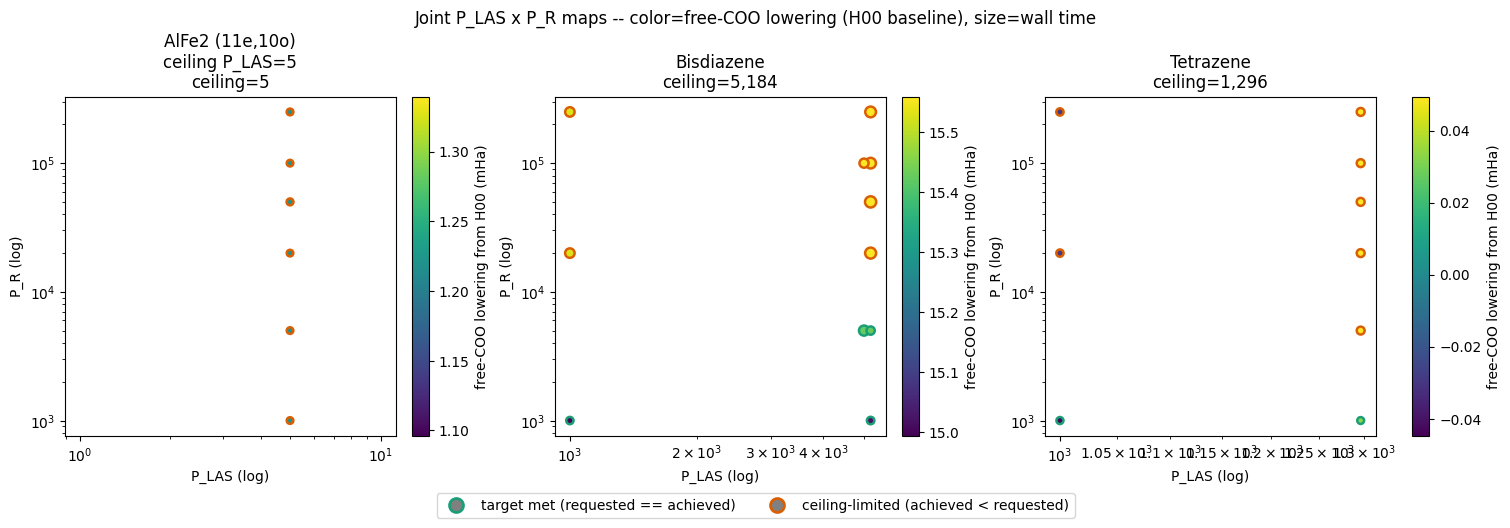

In [1]:

%matplotlib inline
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

COLORBLIND = {
    "cmap": "viridis",
    "ok_edge": "#1B9E77",
    "ceiling_edge": "#D95F02",
    "fail_edge": "#7570B3",
}

sweep_b = json.loads(Path("data/results/01_parent_recovery_lassis/combined_2d_sweep.json").read_text())["systems"]
order_b = ["alfe2_11o10e", "bisdiazene", "c2h6n4_paper"]
labels_b = ["AlFe2 (11e,10o)\nceiling P_LAS=5", "Bisdiazene", "Tetrazene"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), constrained_layout=True)
for ax, key, label in zip(axes, order_b, labels_b):
    entry = sweep_b[key]
    pts = entry["points"]
    xs, ys, cs, ss, edges = [], [], [], [], []
    for pt in pts.values():
        if pt.get("failed"):
            continue
        d = pt["determinants"]
        xs.append(max(d["P_LAS_actual"], 1))
        ys.append(d["P_R_requested"])
        cs.append(pt["derived_common_baseline_mha"]["free_coo_total_lowering_from_h00_mha"])
        ss.append(20 + 3.0 * np.sqrt(max(pt["wall_s_total"], 0.01)))
        edges.append(COLORBLIND["ok_edge"] if d["P_R_target_met"] else COLORBLIND["ceiling_edge"])
    sc = ax.scatter(xs, ys, c=cs, s=ss, cmap=COLORBLIND["cmap"], edgecolors=edges,
                     linewidths=1.8, zorder=3)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("P_LAS (log)"); ax.set_ylabel("P_R (log)")
    ax.set_title(f"{label}\nceiling={entry['las_product_ceiling']:,}")
    fig.colorbar(sc, ax=ax, label="free-COO lowering from H00 (mHa)")

legend_elems = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="gray",
           markeredgecolor=COLORBLIND["ok_edge"], markeredgewidth=2, markersize=10,
           label="target met (requested == achieved)"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="gray",
           markeredgecolor=COLORBLIND["ceiling_edge"], markeredgewidth=2, markersize=10,
           label="ceiling-limited (achieved < requested)"),
]
fig.legend(handles=legend_elems, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Joint P_LAS x P_R maps -- color=free-COO lowering (H00 baseline), size=wall time", y=1.04)
plt.show()


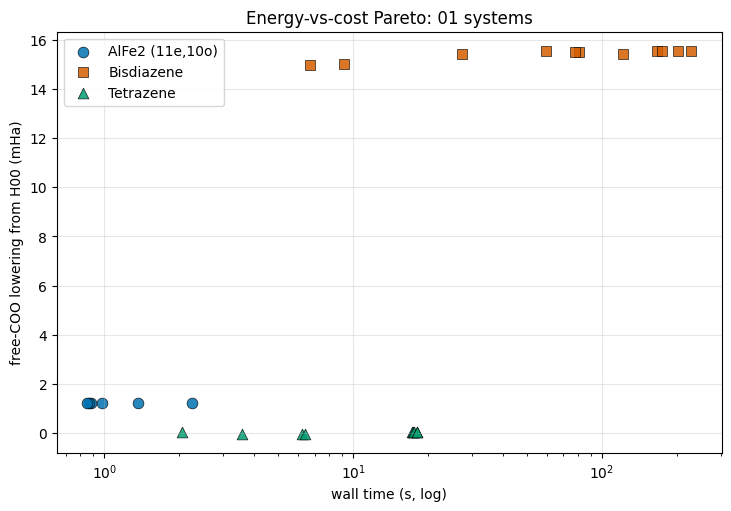

In [2]:

fig, ax = plt.subplots(figsize=(7.2, 5.0), constrained_layout=True)
markers = {"alfe2_11o10e": "o", "bisdiazene": "s", "c2h6n4_paper": "^"}
colors = {"alfe2_11o10e": "#0072B2", "bisdiazene": "#D55E00", "c2h6n4_paper": "#009E73"}
for key, label in zip(order_b, labels_b):
    entry = sweep_b[key]
    xs, ys = [], []
    for pt in entry["points"].values():
        if pt.get("failed"):
            continue
        xs.append(pt["wall_s_total"])
        ys.append(pt["derived_common_baseline_mha"]["free_coo_total_lowering_from_h00_mha"])
    ax.scatter(xs, ys, marker=markers[key], color=colors[key], label=label.split("\n")[0],
               s=60, alpha=0.85, edgecolors="black", linewidths=0.5)
ax.set_xscale("log")
ax.set_xlabel("wall time (s, log)")
ax.set_ylabel("free-COO lowering from H00 (mHa)")
ax.set_title("Energy-vs-cost Pareto: 01 systems")
ax.legend()
ax.grid(alpha=0.3)
plt.show()


System          Selected point                Parent E    free-COO E  Lowering(mHa)      LASSIS E LASSIS OK?
AlFe2 (11e,10o) P_LAS=5_P_R=100000        -3971.791491  -3971.792709         1.2178  -3971.792767       True
Bisdiazene      P_LAS=5184_P_R=100000      -295.569433   -295.584992        15.5589   -295.573523       True
Tetrazene       P_LAS=1296_P_R=5000        -296.879529   -296.879579         0.0495   -296.879559       True


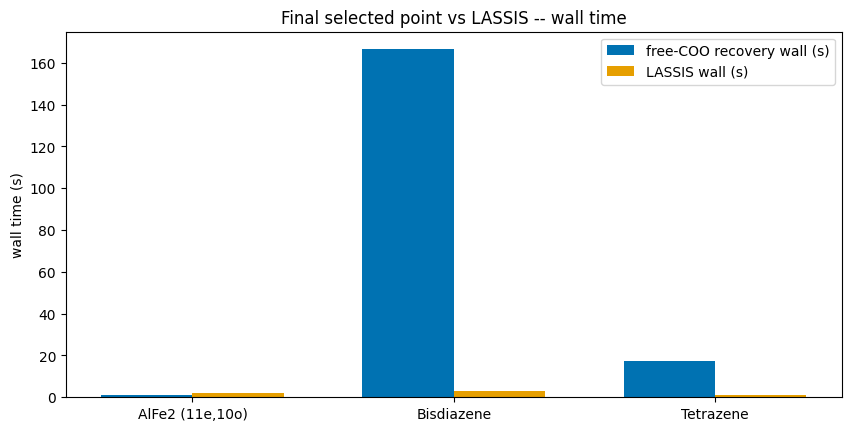

In [3]:

pilot = json.loads(Path("data/results/01_parent_recovery_lassis/systems_pilot.json").read_text())["data"]

def select_final_point(points):
    valid = [(label, pt) for label, pt in points.items() if not pt.get("failed")]
    valid.sort(key=lambda kv: kv[1]["energies_ha"]["free_coo_after"])
    best_label, best_pt = valid[0]
    best_e = best_pt["energies_ha"]["free_coo_after"]
    ties = [(l, p) for l, p in valid if p["energies_ha"]["free_coo_after"] - best_e < 1e-6]
    ties.sort(key=lambda kv: kv[1]["wall_s_total"])
    return ties[0]

rows = []
for key, label in zip(order_b, labels_b):
    entry = sweep_b[key]
    sel_label, sel_pt = select_final_point(entry["points"])
    h00 = entry["parent"]["e_tot"]
    lassis_e = pilot[key]["workflow2_phased_parent_lassis"]["lassis"]["e_ground"]
    lassis_variational = pilot[key]["workflow2_phased_parent_lassis"]["lassis"]["variational_vs_parent"]
    lassis_wall = pilot[key]["workflow2_phased_parent_lassis"]["lassis"]["wall_s"]
    rows.append(dict(
        system=label.split("\n")[0], selected_point=sel_label,
        parent_e=h00, free_coo_e=sel_pt["energies_ha"]["free_coo_after"],
        lowering_mha=sel_pt["derived_common_baseline_mha"]["free_coo_total_lowering_from_h00_mha"],
        lassis_e=lassis_e, lassis_variational=lassis_variational,
        recovery_wall_s=sel_pt["wall_s_total"], lassis_wall_s=lassis_wall,
        p_las=sel_pt["determinants"]["P_LAS_actual"], p_r=sel_pt["determinants"]["P_R_achieved"],
    ))

print(f"{'System':<16}{'Selected point':<24}{'Parent E':>14}{'free-COO E':>14}{'Lowering(mHa)':>15}{'LASSIS E':>14}{'LASSIS OK?':>11}")
for r in rows:
    print(f"{r['system']:<16}{r['selected_point']:<24}{r['parent_e']:>14.6f}{r['free_coo_e']:>14.6f}"
          f"{r['lowering_mha']:>15.4f}{r['lassis_e']:>14.6f}{str(r['lassis_variational']):>11}")

fig, ax = plt.subplots(figsize=(8.4, 4.2), constrained_layout=True)
x = np.arange(len(rows))
width = 0.35
ax.bar(x - width/2, [r["recovery_wall_s"] for r in rows], width, label="free-COO recovery wall (s)", color="#0072B2")
ax.bar(x + width/2, [r["lassis_wall_s"] for r in rows], width, label="LASSIS wall (s)", color="#E69F00")
ax.set_xticks(x); ax.set_xticklabels([r["system"] for r in rows])
ax.set_ylabel("wall time (s)")
ax.set_title("Final selected point vs LASSIS -- wall time")
ax.legend()
plt.show()
